# Supplementary figures

Each code cell is identical to the script named above it, which `make figures` runs to
write the PDF to `figures/`. The cells read the data in `data/generated/` (see the
README) and can be run in any order.

## Figure S1
`scripts/figures/markov_td_sim.py`

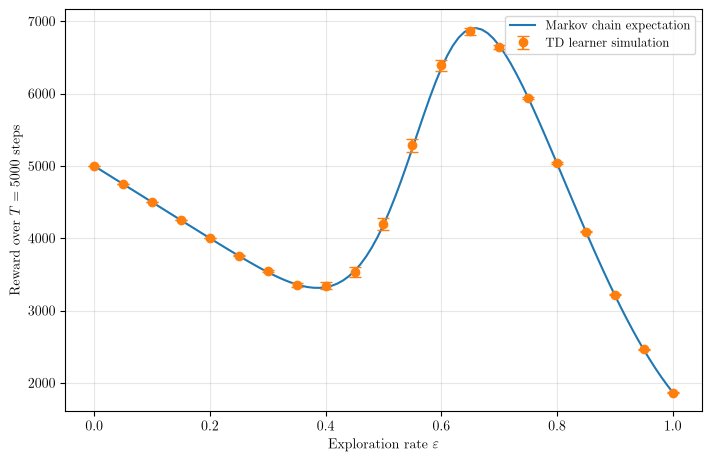

In [1]:
"""Figure S1: the Markov chain reproduces the mean reward of simulated TD learners."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import save_figure, use_paper_style

use_paper_style()
data = np.load(DATA_DIR / "td_learner_sim.npz")

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.plot(data["chain_eps"], data["expected_reward"], label="Markov chain expectation")
ax.errorbar(
    data["sim_eps"],
    data["mean_reward"],
    yerr=2 * data["standard_error"],
    fmt="o",
    capsize=4,
    label="TD learner simulation",
)
ax.set_xlabel(r"Exploration rate $\varepsilon$")
ax.set_ylabel(rf"Reward over $T = {data['T']}$ steps")
ax.legend()
ax.grid(True)

save_figure(fig, "markov_td_sim.pdf")

## Figure S2
`scripts/figures/threshold_reward_ratio.py`

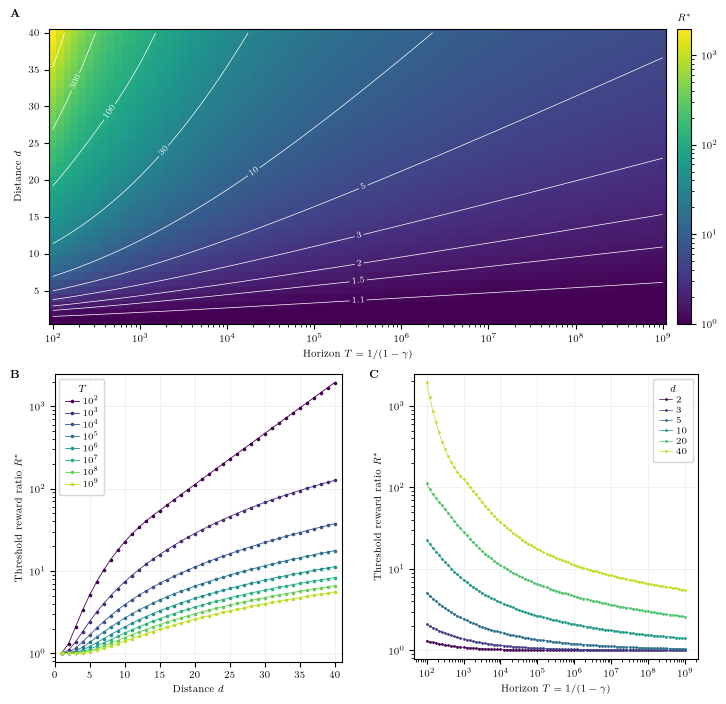

In [2]:
"""Figure S2: the threshold reward ratio R* at which exploring first pays, over the distance
d and the horizon T = 1/(1 - gamma), with slices at fixed T and at fixed d."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from scipy.interpolate import RectBivariateSpline

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import CM, PNAS_WIDTHS, save_figure, use_paper_style

use_paper_style(final_size=True)
data = np.load(DATA_DIR / "threshold_sweep.npz")
R, T, d = data["R_star"], data["T_values"], data["d_values"]  # R has shape (T, d)
logT = np.log10(T)

SHOWN_T = 10.0 ** np.arange(2, 10)
SHOWN_D = [2, 3, 5, 10, 20, 40]
LEVELS = [1.1, 1.5, 2, 3, 5, 10, 30, 100, 300, 1000]
LEGEND_KW = dict(handlelength=1.5, handletextpad=0.4, labelspacing=0.25, borderpad=0.7)


def contour_midpoints(ax, cs):
    """Label positions halfway along each level's longest piece, in screen distance.

    Levels whose contour is too short to hold a label (a corner of the plot) are left
    unlabeled."""
    points = []
    for segs in cs.allsegs:
        if not segs:
            continue
        xy = ax.transData.transform(max(segs, key=len))
        arc = np.r_[0, np.cumsum(np.hypot(*np.diff(xy, axis=0).T))]
        if arc[-1] >= 0.25 * ax.bbox.height:
            points.append(ax.transData.inverted().transform(xy[np.searchsorted(arc, arc[-1] / 2)]))
    return points


fig = plt.figure(figsize=(PNAS_WIDTHS["double"], 17.5 * CM), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1.08, 1])
sub_b, sub_c = bottom.subfigures(1, 2)
for subfig, letter in [(top, "A"), (sub_b, "B"), (sub_c, "C")]:
    subfig.text(0, 1, rf"\textbf{{{letter}}}", ha="left", va="top", fontsize=8)

# A: heatmap over (T, d). The x axis is log10 T on a linear scale, because clabel cuts the
# wrong stretch of line on a log axis, so the decade labels and minor ticks are set by hand.
# Contours come from a cubic spline of log R*; levels below R*(d = 2) are omitted, since
# R* = 1 at d = 1 and such a contour would only interpolate between those two rows.
ax = top.subplots()
mesh = ax.pcolormesh(logT, d, R.T, norm=LogNorm(1, R.max()), shading="nearest", rasterized=True)
spline = RectBivariateSpline(logT, d, np.log(R))
logT_fine, d_fine = np.linspace(logT[0], logT[-1], 600), np.linspace(d[0], d[-1], 400)
levels = [v for v in LEVELS if R[:, 1].min() < v < R.max()]
cs = ax.contour(logT_fine, d_fine, np.exp(spline(logT_fine, d_fine)).T, levels=levels, colors="w", linewidths=0.5)
half_step = (logT[1] - logT[0]) / 2
ax.set_xlim(logT[0] - half_step, logT[-1] + half_step)
ax.set_ylim(d[0] - 0.5, d[-1] + 0.5)
decades = np.arange(np.ceil(logT[0]), np.floor(logT[-1]) + 1)
ax.set_xticks(decades, [rf"$10^{{{t:.0f}}}$" for t in decades])
minor = np.log10(np.outer(10.0**decades, np.arange(2, 10)).ravel())
ax.set_xticks(minor[(minor > logT[0]) & (minor < logT[-1])], minor=True)
ax.set_xlabel(r"Horizon $T = 1/(1-\gamma)$")
ax.set_ylabel(r"Distance $d$")
colorbar = top.colorbar(mesh, ax=ax, pad=0.01, fraction=0.03, aspect=20)
colorbar.ax.set_title(r"$R^*$", fontsize=plt.rcParams["font.size"])
fig.canvas.draw()  # fix the layout before placing the labels in screen coordinates
ax.clabel(cs, fmt=lambda v: f"{v:g}", fontsize=6, inline_spacing=2, manual=contour_midpoints(ax, cs))

# B: R* against d at one horizon per decade.
ax_b = sub_b.subplots()
for T_shown, color in zip(SHOWN_T, plt.cm.viridis(np.linspace(0, 0.9, len(SHOWN_T)))):
    row = int(np.argmin(np.abs(np.log(T / T_shown))))
    ax_b.plot(d, R[row], "o-", ms=1.6, lw=0.6, color=color, label=rf"$10^{{{np.log10(T_shown):.0f}}}$")
ax_b.set_xlim(0, d[-1] + 1)
ax_b.set_xlabel(r"Distance $d$")
ax_b.legend(loc="upper left", title=r"$T$", **LEGEND_KW)

# C: R* against T at select distances.
ax_c = sub_c.subplots()
for d_shown, color in zip(SHOWN_D, plt.cm.viridis(np.linspace(0, 0.9, len(SHOWN_D)))):
    col = list(d).index(d_shown)
    ax_c.plot(T, R[:, col], "o-", ms=1.0, lw=0.5, color=color, label=rf"${d_shown}$")
ax_c.set_xscale("log")
ax_c.set_xlabel(r"Horizon $T = 1/(1-\gamma)$")
ax_c.legend(loc="upper right", title=r"$d$", **LEGEND_KW)

# R* >= 1, so the data fill log10 R* in [0, span]; pad 3% of the panel height at each end.
span = np.log10(R.max())
for ax in [ax_b, ax_c]:
    ax.set_box_aspect(1)
    ax.set_yscale("log")
    ax.set_ylim(10.0 ** (-0.03 * span), 10.0 ** (1.03 * span))
    ax.set_ylabel(r"Threshold reward ratio $R^*$")
    ax.grid(True, lw=0.4)

save_figure(fig, "threshold_reward_ratio.pdf")

## Figure S3
`scripts/figures/opt_eps_poisson.py`

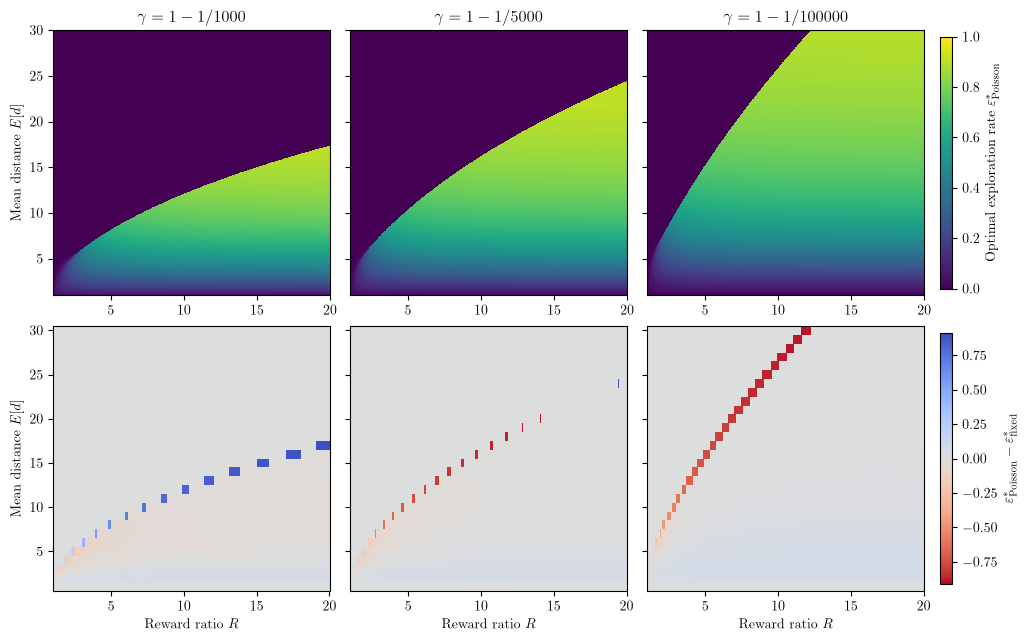

In [3]:
"""Figure S3: optimal exploration rate when the distance is random, d ~ Poisson + 1,
and its difference from the optimum at the matching fixed distance."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style()
poisson = np.load(DATA_DIR / "opt_eps_poisson.npz")
comparison = np.load(DATA_DIR / "opt_eps_poisson_comparison.npz")
T_values = poisson["T_values"]
difference = comparison["difference"]
limit = np.abs(difference).max()

fig, axes = plt.subplots(
    2,
    len(T_values),
    figsize=(10.15, 6.3),
    sharex="row",
    sharey="row",
    layout="constrained",
)
for t, T in enumerate(T_values):
    top = axes[0, t].pcolormesh(
        centers_to_edges(poisson["R_values"]),
        centers_to_edges(poisson["mean_distances"]),
        poisson["opt_eps"][t],
        cmap="viridis",
        vmin=0,
        vmax=1,
        rasterized=True,
    )
    bottom = axes[1, t].pcolormesh(
        centers_to_edges(comparison["R_values"]),
        centers_to_edges(comparison["d_values"]),
        difference[t],
        cmap="coolwarm_r",
        vmin=-limit,
        vmax=limit,
        rasterized=True,
    )
    axes[0, t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[1, t].set_xlabel(r"Reward ratio $R$")
for row in axes[:, 0]:
    row.set_ylabel(r"Mean distance $E[d]$")

fig.colorbar(top, ax=axes[0], pad=0.01, shrink=0.95).set_label(
    r"Optimal exploration rate $\varepsilon^*_{\mathrm{Poisson}}$"
)
fig.colorbar(bottom, ax=axes[1], pad=0.01, shrink=0.95).set_label(
    r"$\varepsilon^*_{\mathrm{Poisson}} - \varepsilon^*_{\mathrm{fixed}}$"
)

save_figure(fig, "opt_eps_poisson.pdf")

## Figure S4
`scripts/figures/sym_local_nash_location.py`

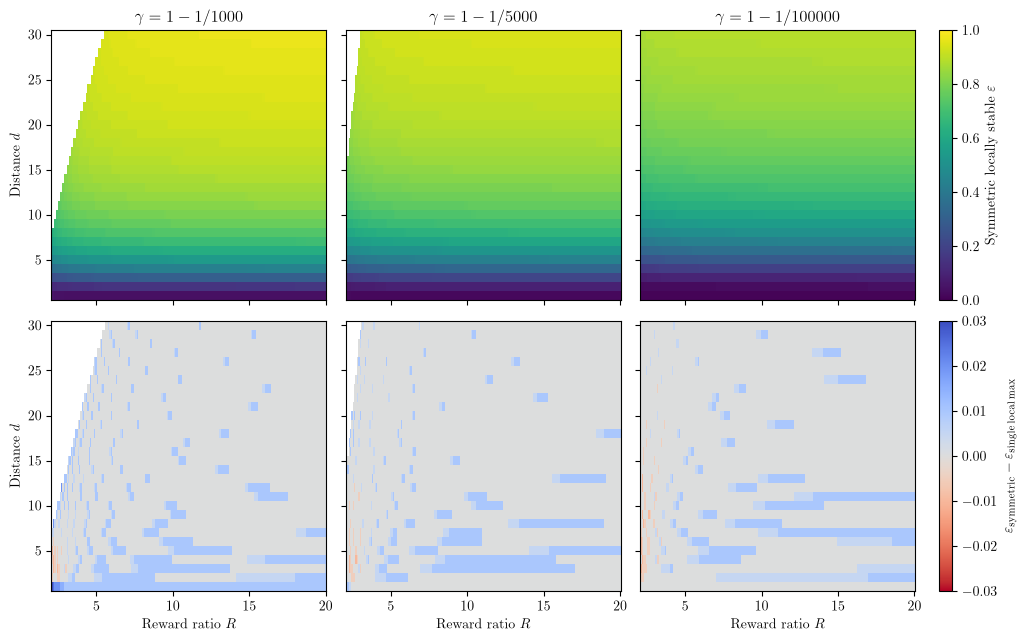

In [4]:
"""Figure S4: rate at the symmetric locally stable point, and its difference from the
rate at the positive local maximum of a lone agent's reward curve."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style()
sweep = np.load(DATA_DIR / "sweep_nash_social_dilemma_fine.npz")
single = np.load(DATA_DIR / "local_max_eps_single.npz")
symmetric_eps = sweep["symmetric_eps"]
difference = symmetric_eps - single["local_max_eps"]
limit = np.nanmax(np.abs(difference))
R_edges = centers_to_edges(sweep["R_values"])
d_edges = centers_to_edges(sweep["d_values"])

fig, axes = plt.subplots(
    2,
    len(sweep["T_values"]),
    figsize=(10.15, 6.3),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for t, T in enumerate(sweep["T_values"]):
    top = axes[0, t].pcolormesh(
        R_edges,
        d_edges,
        np.ma.masked_invalid(symmetric_eps[t]),
        cmap="viridis",
        vmin=0,
        vmax=1,
        rasterized=True,
    )
    bottom = axes[1, t].pcolormesh(
        R_edges,
        d_edges,
        np.ma.masked_invalid(difference[t]),
        cmap="coolwarm_r",
        norm=TwoSlopeNorm(0, -limit, limit),
        rasterized=True,
    )
    axes[0, t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[1, t].set_xlabel(r"Reward ratio $R$")
for row in axes[:, 0]:
    row.set_ylabel(r"Distance $d$")

fig.colorbar(top, ax=axes[0], pad=0.02).set_label(
    r"Symmetric locally stable $\varepsilon$"
)
fig.colorbar(bottom, ax=axes[1], pad=0.02).set_label(
    r"$\varepsilon_{\mathrm{symmetric}} - \varepsilon_{\mathrm{single\,local\,max}}$"
)

save_figure(fig, "sym_local_nash_location.pdf")

## Figure S5
`scripts/figures/worst_equilibrium_fitness_percentages.py`

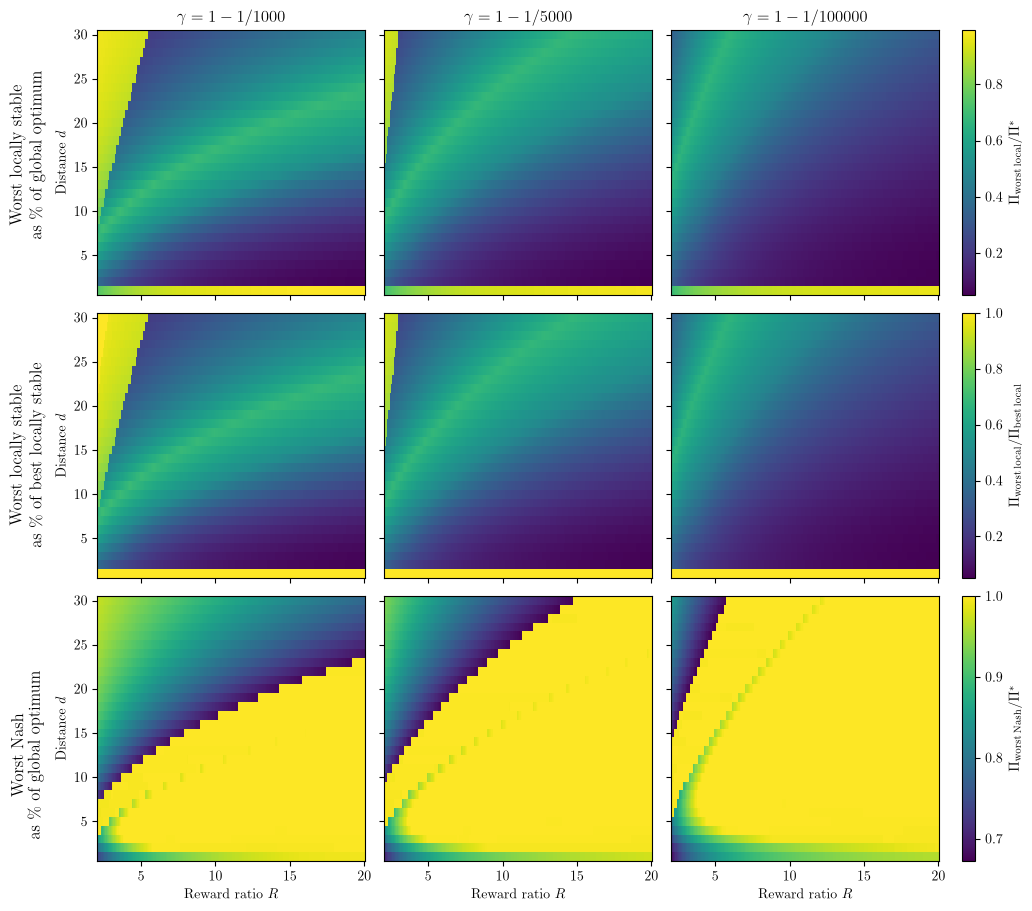

In [5]:
"""Figure S5: collective payoff at the worst locally stable point and at the worst Nash
equilibrium, relative to the global optimum and to the best locally stable point."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FormatStrFormatter

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style()
sweep = np.load(DATA_DIR / "sweep_nash_social_dilemma_fine.npz")
small_d = np.load(DATA_DIR / "sweep_nash_social_dilemma_small_d.npz")
T_values = sweep["T_values"]

# The shortest distances come from the sweep that adds rates close to zero.
payoff = {}
replace = np.isin(sweep["d_values"], small_d["d_values"])
for key in [
    "worst_local_payoff",
    "best_local_payoff",
    "worst_nash_payoff",
    "global_optimum_payoff",
]:
    payoff[key] = sweep[key].copy()
    payoff[key][:, replace] = small_d[key]

rows = [
    (
        payoff["worst_local_payoff"] / payoff["global_optimum_payoff"],
        r"$\Pi_{\mathrm{worst\,local}}/\Pi^*$",
        r"\shortstack{Worst locally stable\\as \% of global optimum}",
    ),
    (
        payoff["worst_local_payoff"] / payoff["best_local_payoff"],
        r"$\Pi_{\mathrm{worst\,local}}/\Pi_{\mathrm{best\,local}}$",
        r"\shortstack{Worst locally stable\\as \% of best locally stable}",
    ),
    (
        payoff["worst_nash_payoff"] / payoff["global_optimum_payoff"],
        r"$\Pi_{\mathrm{worst\,Nash}}/\Pi^*$",
        r"\shortstack{Worst Nash\\as \% of global optimum}",
    ),
]

R_edges = centers_to_edges(sweep["R_values"])
d_edges = centers_to_edges(sweep["d_values"])
fig, axes = plt.subplots(
    len(rows),
    len(T_values),
    figsize=(9.75, 9),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for row, (ratio, colorbar_label, row_label) in enumerate(rows):
    norm = plt.Normalize(np.nanmin(ratio), np.nanmax(ratio))
    for t, T in enumerate(T_values):
        image = axes[row, t].pcolormesh(
            R_edges,
            d_edges,
            ratio[t],
            cmap="viridis",
            norm=norm,
            antialiased=False,
            rasterized=True,
        )
    colorbar = fig.colorbar(image, ax=axes[row], fraction=0.025, pad=0.02)
    colorbar.set_label(colorbar_label)
    axes[row, 0].set_ylabel(r"Distance $d$")
    fig.text(
        -0.025,
        1 - (row + 0.5) / len(rows),
        row_label,
        rotation=90,
        ha="center",
        va="center",
        fontsize=plt.rcParams["axes.titlesize"],
    )

# The bottom row's scale starts well above zero; label it in steps of 0.1.
colorbar.set_ticks(np.arange(np.ceil(norm.vmin * 10) / 10, norm.vmax + 1e-9, 0.1))
colorbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

for t, T in enumerate(T_values):
    axes[0, t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[-1, t].set_xlabel(r"Reward ratio $R$")
for ax in axes.ravel():
    ax.set_xticks([5, 10, 15, 20])
    ax.set_yticks([5, 10, 15, 20, 25, 30])

save_figure(fig, "worst_equilibrium_fitness_percentages.pdf")

## Figure S6
`scripts/figures/local_br_mean_fitness_ratio.py`

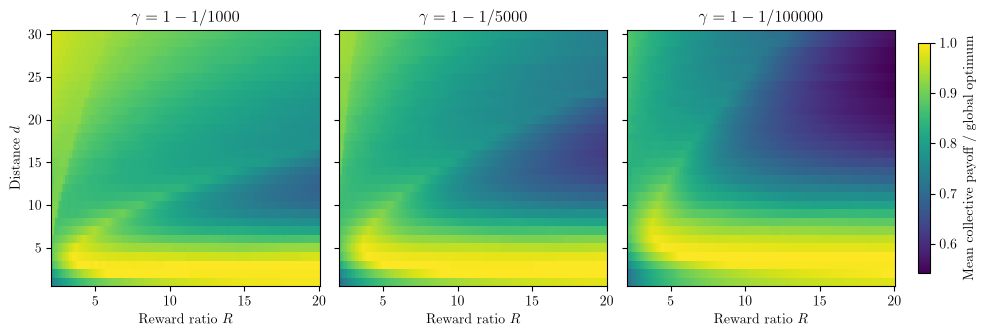

In [6]:
"""Figure S6: collective payoff reached by the local best-response dynamics, averaged
over starting pairs, relative to the global optimum."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style()
data = np.load(DATA_DIR / "local_br_outcomes.npz")
ratio = data["mean_payoff"] / data["global_optimum_payoff"]

fig, axes = plt.subplots(
    1,
    len(data["T_values"]),
    figsize=(9.75, 3.25),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for t, T in enumerate(data["T_values"]):
    image = axes[t].pcolormesh(
        centers_to_edges(data["R_values"]),
        centers_to_edges(data["d_values"]),
        ratio[t],
        cmap="viridis",
        vmin=ratio.min(),
        vmax=ratio.max(),
        rasterized=True,
    )
    axes[t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[t].set_xlabel(r"Reward ratio $R$")
axes[0].set_ylabel(r"Distance $d$")

fig.colorbar(image, ax=axes, pad=0.02, shrink=0.9).set_label(
    "Mean collective payoff / global optimum"
)

save_figure(fig, "local_br_mean_fitness_ratio.pdf")

## Figure S7
`scripts/figures/global_social_optimum_classification.py`

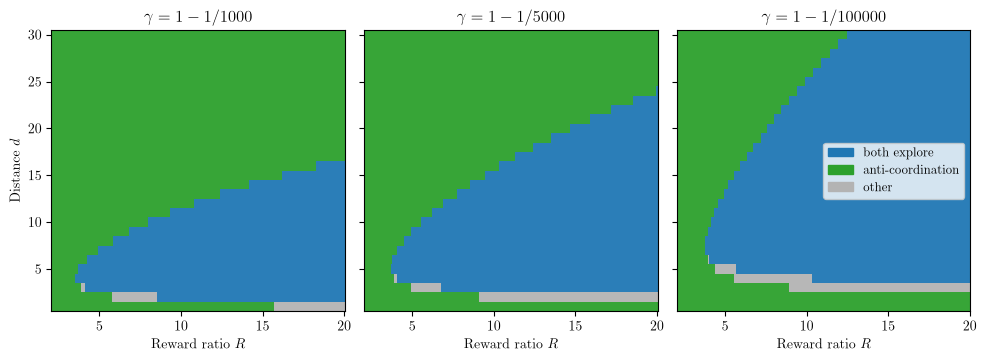

In [7]:
"""Figure S7: type of the strategy pair that maximizes the collective payoff."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    OUTCOME_CMAP,
    OUTCOME_LABELS,
    OUTCOME_NORM,
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style()
data = np.load(DATA_DIR / "sweep_nash_social_dilemma_fine401.npz")
optimum_type = data["global_optimum_type"]

fig, axes = plt.subplots(
    1,
    len(data["T_values"]),
    figsize=(9.75, 3.5),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for t, T in enumerate(data["T_values"]):
    axes[t].pcolormesh(
        centers_to_edges(data["R_values"]),
        centers_to_edges(data["d_values"]),
        optimum_type[t],
        cmap=OUTCOME_CMAP,
        norm=OUTCOME_NORM,
        alpha=0.95,
        antialiased=False,
        rasterized=True,
    )
    axes[t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[t].set_xlabel(r"Reward ratio $R$")
    axes[t].set_xticks([5, 10, 15, 20])
    axes[t].set_yticks([5, 10, 15, 20, 25, 30])
axes[0].set_ylabel(r"Distance $d$")

axes[-1].legend(
    handles=[
        Patch(color=OUTCOME_CMAP(code), label=OUTCOME_LABELS[code])
        for code in np.unique(optimum_type)
    ],
    loc="center right",
)

save_figure(fig, "global_social_optimum_classification.pdf")

## Figure S8
`scripts/figures/two_site_model.py`

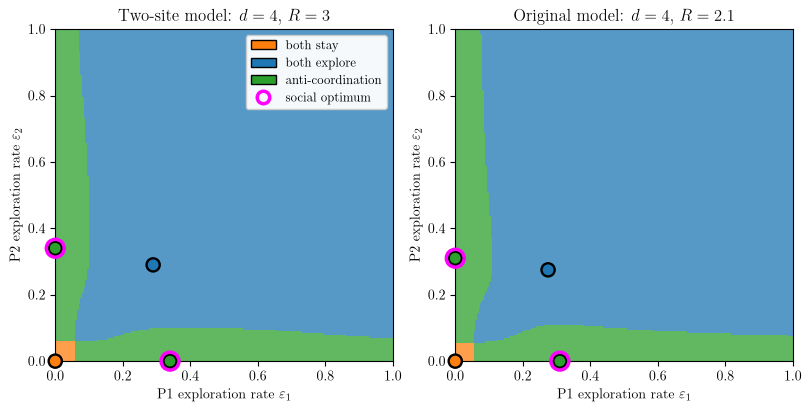

In [8]:
"""Figure S8: local best-response basins in the two-site model and the lattice model."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    OUTCOME_CMAP,
    OUTCOME_LABELS,
    SOCIAL_OPTIMUM_COLOR,
    plot_basins,
    save_figure,
    use_paper_style,
)

use_paper_style()
two_site = np.load(DATA_DIR / "two_site_local_br.npz")
lattice = np.load(DATA_DIR / "two_agent_local_br.npz")
k = list(zip(lattice["d_values"], lattice["R_values"])).index((4, 2.1))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
plot_basins(
    axes[0],
    two_site["eps_grid"],
    two_site["codes"],
    two_site["endpoints"],
    two_site["social_optimum"],
)
axes[0].set_title(rf"Two-site model: $d = {two_site['d']}$, $R = {two_site['R']:g}$")
plot_basins(
    axes[1],
    lattice["eps_grid"],
    lattice["codes"][k],
    lattice["endpoints"][k],
    lattice["social_optimum"][k],
)
axes[1].set_title(r"Original model: $d = 4$, $R = 2.1$")

for ax in axes:
    ax.set_xlabel(r"P1 exploration rate $\varepsilon_1$")
    ax.set_ylabel(r"P2 exploration rate $\varepsilon_2$")

axes[0].legend(
    handles=[
        Patch(
            facecolor=OUTCOME_CMAP(code), edgecolor="black", label=OUTCOME_LABELS[code]
        )
        for code in np.unique(two_site["codes"])
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            linestyle="none",
            markerfacecolor="none",
            markeredgecolor=SOCIAL_OPTIMUM_COLOR,
            markeredgewidth=2.5,
            markersize=9,
            label="social optimum",
        )
    ],
    loc="upper right",
    framealpha=0.95,
)

save_figure(fig, "two_site_model.pdf")

## Figure S9
`scripts/figures/hitting_stats.py`

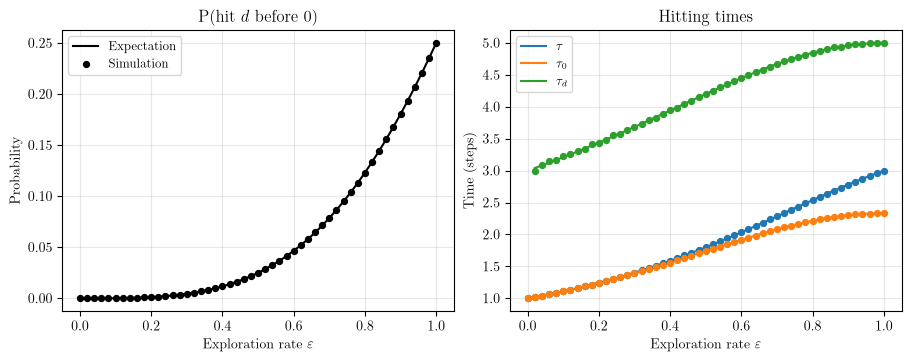

In [9]:
"""Figure S9: probability and time for a walker to reach site d before returning to
site 0, from the gambler's-ruin formulas (curves) and simulation (points)."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import save_figure, use_paper_style

use_paper_style()
data = np.load(DATA_DIR / "hitting_stats.npz")
eps_grid, exact, simulated = data["eps_grid"], data["exact"], data["simulated"]

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")

left.plot(eps_grid, exact[:, 0], color="black", label="Expectation")
left.scatter(
    eps_grid, simulated[:, 0], color="black", s=18, zorder=3, label="Simulation"
)
left.set_title(r"$\mathrm{P}(\mathrm{hit}\ d\ \mathrm{before}\ 0)$")
left.set_ylabel("Probability")

# Columns 1-3: unconditional time, time given d first, time given 0 first.
for column, color, label in [
    (1, "C0", r"$\tau$"),
    (3, "C1", r"$\tau_0$"),
    (2, "C2", r"$\tau_d$"),
]:
    right.plot(eps_grid, exact[:, column], color=color, label=label)
    right.scatter(eps_grid, simulated[:, column], color=color, s=18, zorder=3)
right.set_title("Hitting times")
right.set_ylabel("Time (steps)")

for ax in (left, right):
    ax.set_xlabel(r"Exploration rate $\varepsilon$")
    ax.legend()
    ax.grid(True)

save_figure(fig, "hitting_stats.pdf")